<a href="https://colab.research.google.com/github/hugolo000/DigitalImage_PROJECT/blob/main/notebooks/02_image_preprocessing_ip.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install / upgrade dependencies (Colab usually ships an older albumentations)
!pip install -q -U albumentations opencv-python-headless


# 02 - Image preprocessing and data augmentation

This notebook prepares the CamVid images so the model can use them. It loads the data, defines the preprocessing and augmentation pipelines, shows before/after examples and builds the DataLoaders used for training in notebook 03.

## 1. Data loading (CamVid)
Downloads CamVid (street photos with a *mask* per image, where each pixel stores its class) and builds the train / validation / test lists.

In [ ]:
import os
import zipfile
import urllib.request
from pathlib import Path
import pandas as pd

# Same download logic as notebook 01 (each Colab runtime starts empty)
DATASET_URL = "https://github.com/alexgkendall/SegNet-Tutorial/archive/refs/heads/master.zip"
DATA_DIR = Path("./data")
RAW_ZIP_PATH = DATA_DIR / "camvid_raw.zip"
EXTRACTED_DIR = DATA_DIR / "extracted"

DATA_DIR.mkdir(parents=True, exist_ok=True)
if not RAW_ZIP_PATH.exists():
    print("[INFO] Downloading CamVid dataset...")
    urllib.request.urlretrieve(DATASET_URL, RAW_ZIP_PATH)
if not EXTRACTED_DIR.exists():
    print("[INFO] Unzipping dataset files...")
    with zipfile.ZipFile(RAW_ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACTED_DIR)

BASE_DIR = (EXTRACTED_DIR / "SegNet-Tutorial-master").resolve()

def load_camvid_split(txt_filename: str, base_dir: Path) -> pd.DataFrame:
    """
    Parses a CamVid split text file keeping only the parent folder and file name,
    ignoring the hardcoded absolute paths of the original .txt.
    """
    txt_path = base_dir / "CamVid" / txt_filename
    image_paths, mask_paths = [], []

    with open(txt_path, "r") as file:
        for line in file:
            parts = line.strip().split()
            if len(parts) == 2:
                img_p, mask_p = Path(parts[0]), Path(parts[1])
                img_abs = (base_dir / "CamVid" / img_p.parts[-2] / img_p.parts[-1]).resolve()
                mask_abs = (base_dir / "CamVid" / mask_p.parts[-2] / mask_p.parts[-1]).resolve()
                if img_abs.exists() and mask_abs.exists():
                    image_paths.append(str(img_abs))
                    mask_paths.append(str(mask_abs))
                else:
                    print(f"[WARNING] File not found: {img_abs}")

    return pd.DataFrame({"image_path": image_paths, "mask_path": mask_paths})

df_train = load_camvid_split("train.txt", BASE_DIR)
df_val = load_camvid_split("val.txt", BASE_DIR)
df_test = load_camvid_split("test.txt", BASE_DIR)

assert len(df_train) > 0, "df_train is empty: check the extracted folder structure"
print(f"Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")


Train: 367 | Val: 101 | Test: 233


## 2. Preprocessing and augmentation pipelines
Two pipelines are defined:
- **Train:** resize to 256x256, then random changes (horizontal flip, small brightness/contrast change, blur) so the model sees more variety, and finally normalization.
- **Validation / test:** only resize and normalization, so results are always measured on the same untouched images.

Geometric changes (resize, flip) are applied to the image **and** its mask together; color changes only to the image.

In [ ]:
import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Define standard target dimensions for the model input
IMAGE_HEIGHT = 256
IMAGE_WIDTH = 256

def get_train_transforms():
    """
    Data augmentation and preprocessing pipeline for training images and masks.
    Includes spatial transformations, brightness adjustments, and blurring.
    """
    return A.Compose([
        # 1. Preprocessing: Resize image and mask to fixed target resolution
        A.Resize(height=IMAGE_HEIGHT, width=IMAGE_WIDTH),

        # 2. Augmentation Method 1: Random Horizontal Flip (50% probability)
        A.HorizontalFlip(p=0.5),

        # 3. Augmentation Method 2: Random Brightness & Contrast adjustment
        A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.3),

        # 4. Augmentation Method 3: Gaussian Blur filter for noise/smoothing
        A.GaussianBlur(blur_limit=(3, 5), p=0.2),

        # 5. Normalization and conversion to PyTorch Tensor
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ], is_check_shapes=False)

def get_valid_transforms():
    """
    Minimal preprocessing pipeline for validation and testing sets (no random augmentations).
    """
    return A.Compose([
        A.Resize(height=IMAGE_HEIGHT, width=IMAGE_WIDTH),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ], is_check_shapes=False)

print("Augmentation pipelines successfully defined.")

Augmentation pipelines successfully defined.


## 3. Before / after examples
Visual check that the pipelines work. The first figure shows 4 training images next to their augmented version (with the mean brightness in each title) and the same for the masks. The second figure shows one image under 6 different random augmentations. Results change every time because the augmentation is random.

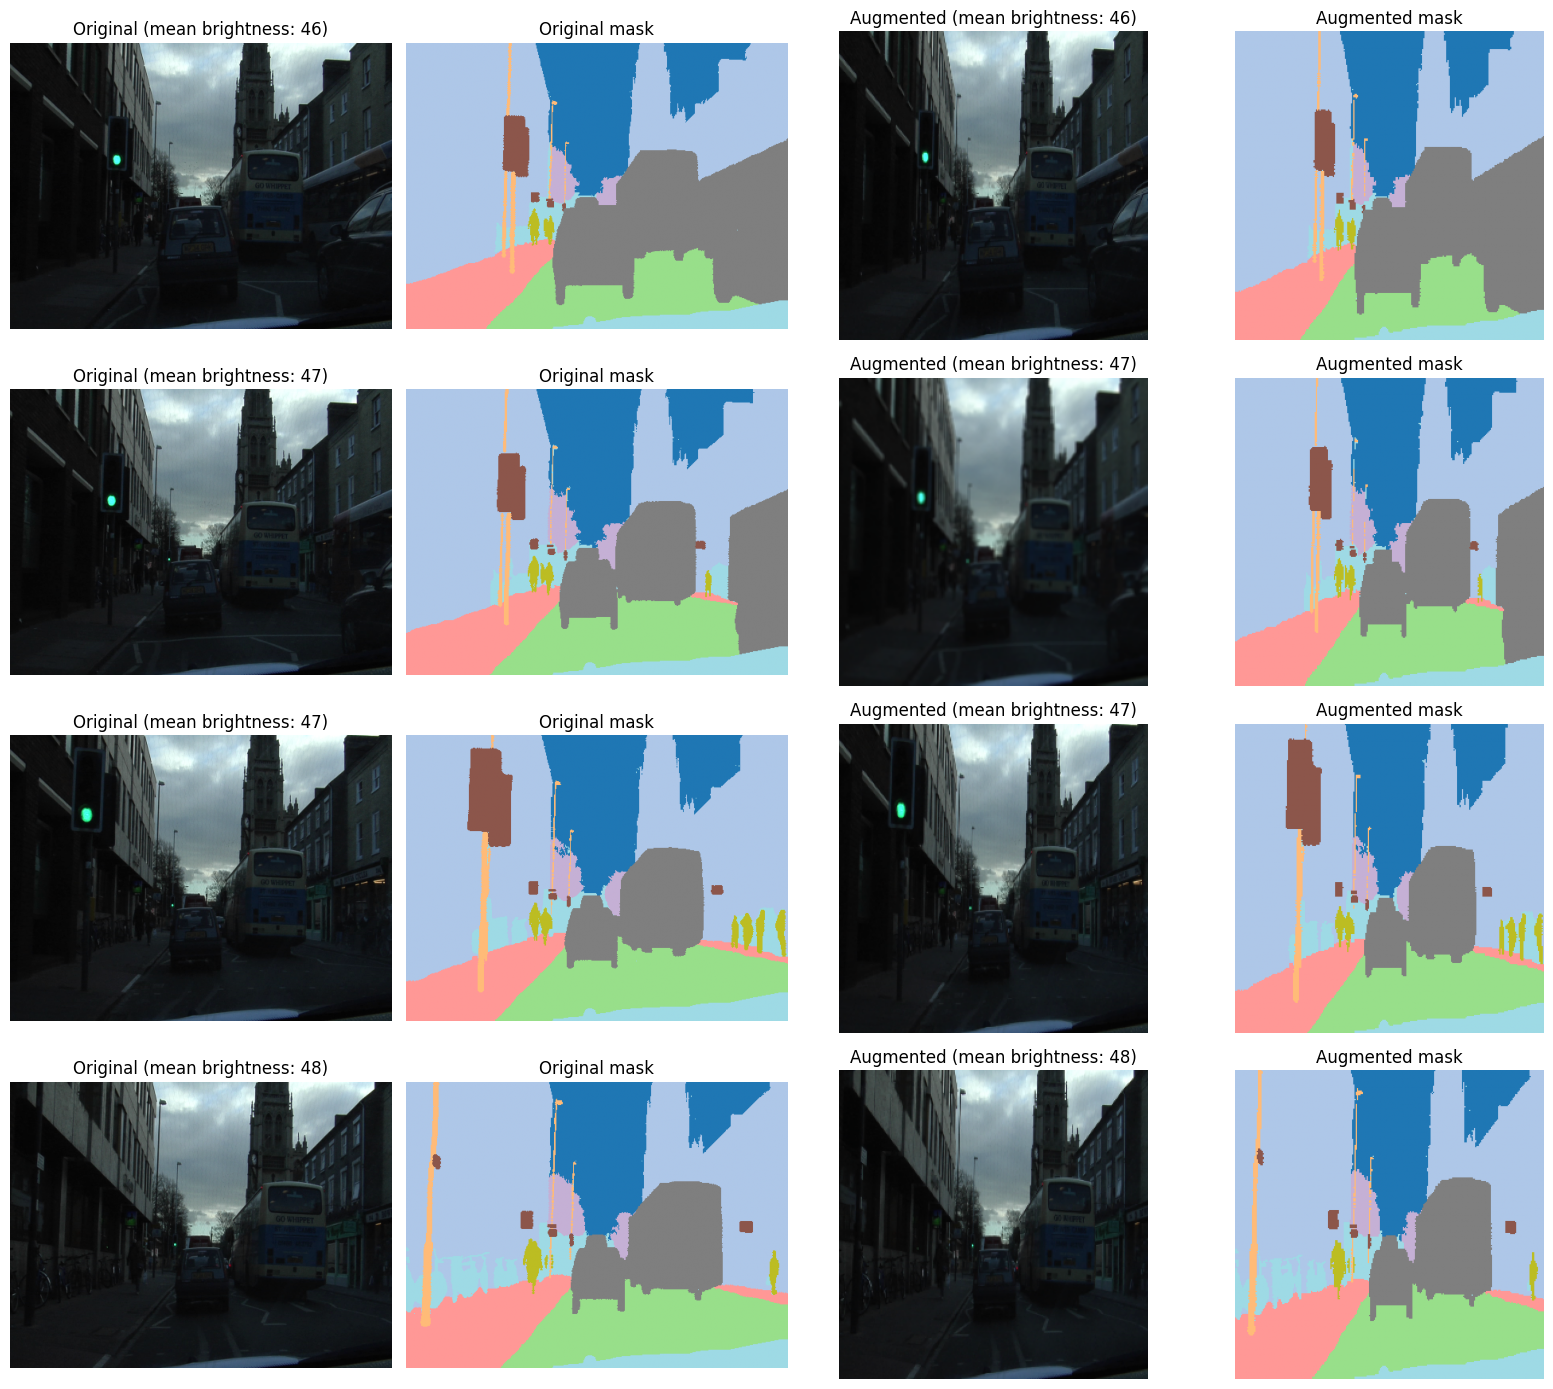

In [ ]:
# Compare original vs augmented training samples (image and mask together)
# Augmentations are random: flips and brightness changes differ on every run.
MEAN = np.array([0.485, 0.456, 0.406])
STD = np.array([0.229, 0.224, 0.225])
transform = get_train_transforms()

num_samples = 4
fig, axes = plt.subplots(num_samples, 4, figsize=(16, 3.5 * num_samples))

for i in range(num_samples):
    image = cv2.cvtColor(cv2.imread(df_train.iloc[i]['image_path']), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(df_train.iloc[i]['mask_path'], cv2.IMREAD_GRAYSCALE)

    out = transform(image=image, mask=mask)
    # Undo normalization only for display purposes
    disp = (out['image'].permute(1, 2, 0).numpy() * STD + MEAN).clip(0, 1)

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(f"Original (mean brightness: {image.mean():.0f})")
    axes[i, 1].imshow(mask, cmap='tab20', vmin=0, vmax=11)
    axes[i, 1].set_title("Original mask")
    axes[i, 2].imshow(disp)
    axes[i, 2].set_title(f"Augmented (mean brightness: {disp.mean() * 255:.0f})")
    axes[i, 3].imshow(out['mask'].numpy(), cmap='tab20', vmin=0, vmax=11)
    axes[i, 3].set_title("Augmented mask")
    for ax in axes[i]:
        ax.axis('off')

plt.tight_layout()
plt.show()

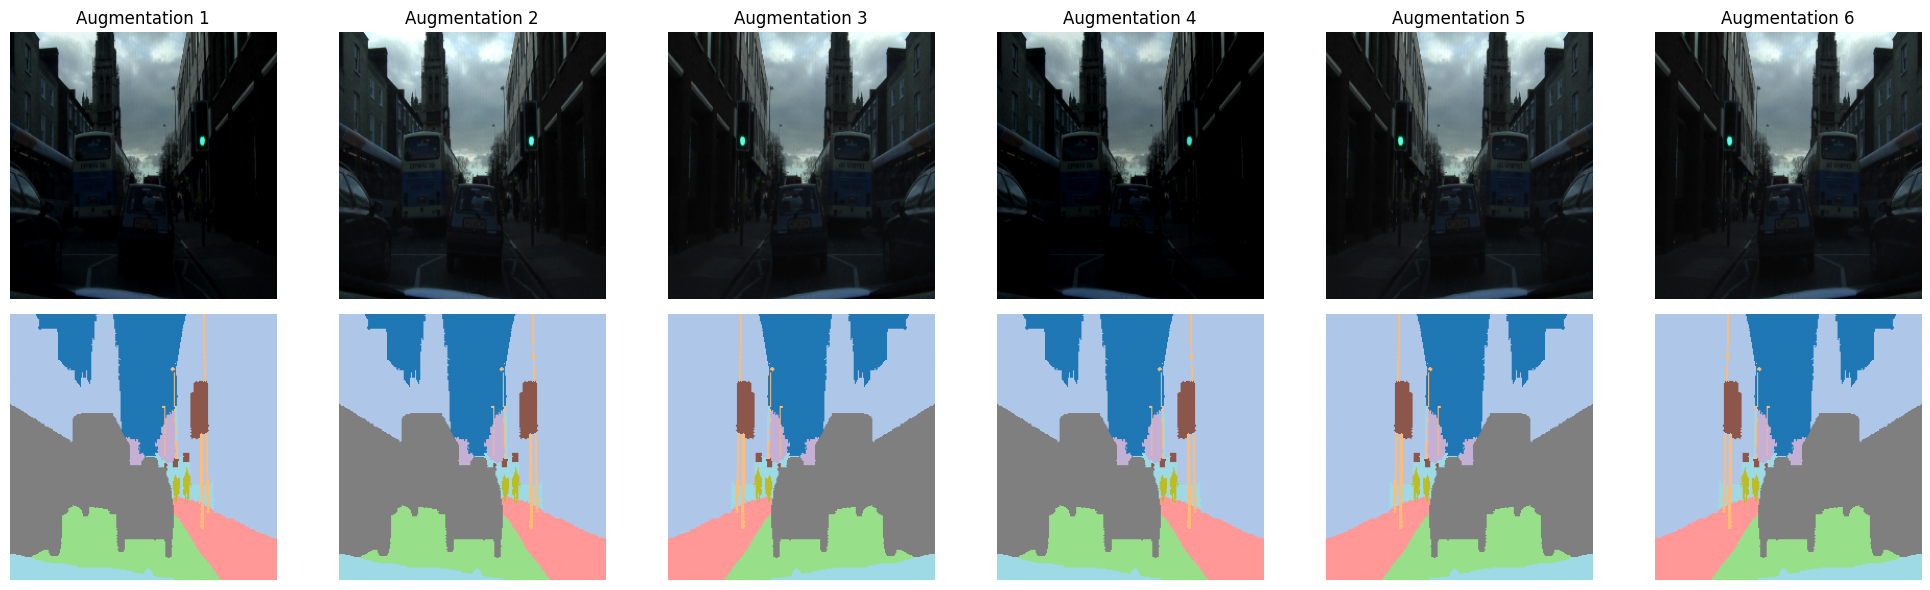

In [ ]:
# Same training sample under 6 different random augmentations
sample = cv2.cvtColor(cv2.imread(df_train.iloc[0]['image_path']), cv2.COLOR_BGR2RGB)
sample_mask = cv2.imread(df_train.iloc[0]['mask_path'], cv2.IMREAD_GRAYSCALE)
transform = get_train_transforms()

fig, axes = plt.subplots(2, 6, figsize=(20, 6))
for j in range(6):
    out = transform(image=sample, mask=sample_mask)
    disp = (out['image'].permute(1, 2, 0).numpy() * STD + MEAN).clip(0, 1)
    axes[0, j].imshow(disp)
    axes[0, j].set_title(f"Augmentation {j + 1}")
    axes[1, j].imshow(out['mask'].numpy(), cmap='tab20', vmin=0, vmax=11)
    axes[0, j].axis('off')
    axes[1, j].axis('off')
plt.tight_layout()
plt.show()

## 4. Dataset class
A `Dataset` tells PyTorch how to read one sample: it loads an image and its mask, applies the pipeline and returns tensors ready for the model.

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

class CamVidDataset(Dataset):
    """
    Custom PyTorch Dataset for CamVid Semantic Segmentation.
    Loads image and mask pairs from DataFrame paths, applies Albumentations
    transformations, and returns PyTorch Tensors ready for model input.
    """
    def __init__(self, df, transform=None):
        self.df = df
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # Extract file paths from the DataFrame
        img_path = self.df.iloc[idx]['image_path']
        mask_path = self.df.iloc[idx]['mask_path']

        # Read image (convert BGR to RGB) and grayscale mask
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        # Apply Albumentations preprocessing and data augmentations
        if self.transform is not None:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']

        # Ensure the mask tensor is cast to torch.long (required for PyTorch loss functions)
        if not isinstance(mask, torch.Tensor):
            mask = torch.tensor(mask, dtype=torch.long)
        else:
            mask = mask.long()

        return image, mask

print("CamVidDataset class successfully defined.")

CamVidDataset class successfully defined.


## 5. DataLoaders
DataLoaders deliver the samples to the model in batches of 8. Only the training one is shuffled.

In [ ]:
# Define hyperparameter for batch processing
BATCH_SIZE = 8
NUM_WORKERS = 2  # Number of parallel data loading processes

# 1. Instantiate PyTorch Datasets using existing DataFrames and transform functions
train_dataset = CamVidDataset(df_train, transform=get_train_transforms())
val_dataset = CamVidDataset(df_val, transform=get_valid_transforms())
test_dataset = CamVidDataset(df_test, transform=get_valid_transforms())

# 2. Instantiate PyTorch DataLoaders
# Shuffle is set to True only for training to randomize sample ordering each epoch
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

print(f"DataLoaders created successfully:")
print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)} | Test batches: {len(test_loader)}")

DataLoaders created successfully:
Train batches: 46 | Val batches: 13 | Test batches: 30


## 6. Batch check
A quick sanity check: it takes one batch and prints the shapes and types of the images and masks.

In [ ]:
# Fetch a single batch from the training DataLoader to verify tensor dimensions and types
images_batch, masks_batch = next(iter(train_loader))

print("=== Batch Verification ===")
print(f"Images batch shape : {images_batch.shape}  -> [Batch Size, Channels, Height, Width]")
print(f"Images data type   : {images_batch.dtype}")
print(f"Masks batch shape  : {masks_batch.shape}  -> [Batch Size, Height, Width]")
print(f"Masks data type    : {masks_batch.dtype}")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


=== Batch Verification ===
Images batch shape : torch.Size([8, 3, 256, 256])  -> [Batch Size, Channels, Height, Width]
Images data type   : torch.float32
Masks batch shape  : torch.Size([8, 256, 256])  -> [Batch Size, Height, Width]
Masks data type    : torch.int64
